<a href="https://colab.research.google.com/github/OlhaMir/testolha/blob/norma/%D0%9B%D0%A06_%D0%9C%D1%96%D1%80%D0%BE%D1%88%D0%BD%D0%B8%D0%BA%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A2_4_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [3]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


**gender** містить стать пацієнта (чоловіча, жіноча або інша).

**age** показує вік у роках.

**hypertension** вказує на наявність гіпертонії: О означає відсутність підвищеного тиску, 1 означає його наявність.

**heart_disease** показує, чи має пацієнт серцево-судинні захворювання: О для «ні», 1 для «так».

**smoking_history** описує історію куріння: людина ніколи не курила, курила раніше, курить зараз, не курить наразі або інформація невідома.

**bmi** (індекс маси тіла) характеризує співвідношення ваги до зросту. HbA1c_level відображає середній рівень цукру в крові за останні 2-3 місяці через показник глікозильованого гемоглобіну.

**blood_glucose_level** містить поточний рівень глюкози в крові на момент вимірювання.

**diabetes** є цільовою ознакою набору даних і показує результат: О означає, що діабету немає, а 1 означає, що діабет діагностовано.

Провести дослідження категоріальних ознак

In [5]:
df.value_counts('gender')

,count
gender,
Female,58552
Male,41430
Other,18


In [6]:
df.value_counts('smoking_history')

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [7]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [8]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [9]:
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [10]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [11]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [14]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

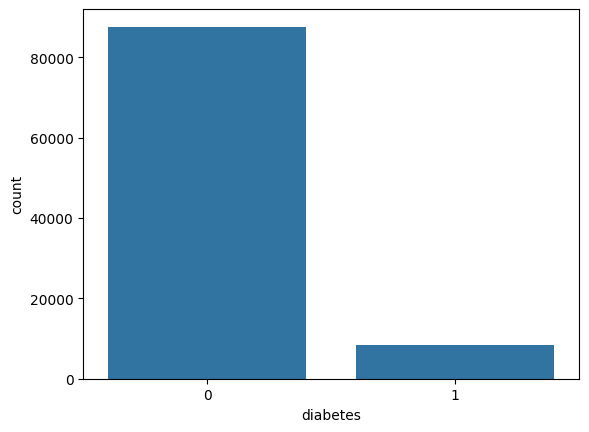

In [15]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [16]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [17]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (76916, 8) Test: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [18]:
cat_cols = ['gender', 'smoking_history']
X_train = pd.get_dummies (X_train, columns=cat_cols, dtype=int)
X_test = pd.get_dummies (X_test, columns=cat_cols, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print('Ознак після кодування:', X_train.shape[1])

Ознак після кодування: 15


In [19]:
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [20]:
X_train.corrwith(y_train).sort_values (ascending=False)

,0
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725
smoking_history_ever,0.020899


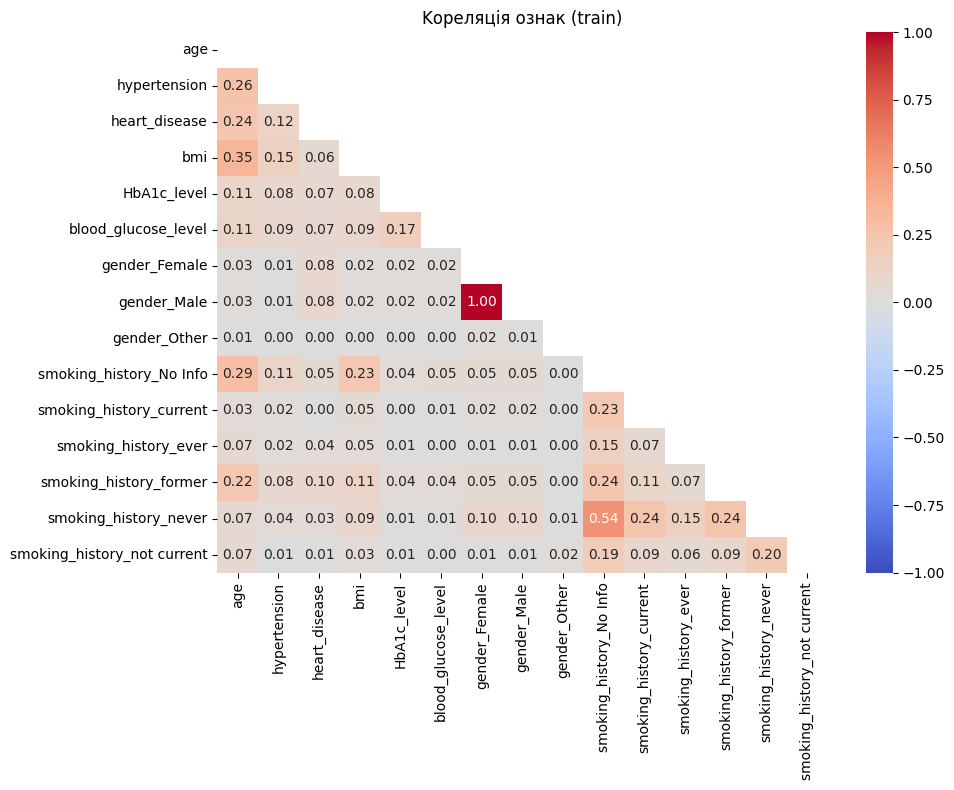

In [21]:
mtx = X_train.corr(numeric_only=True).abs()

plt.figure(figsize=(10, 8))
sns.heatmap(mtx, cmap='coolwarm', annot=True, fmt='.2f',
            mask=np.triu(np.ones_like (mtx, dtype=bool)),
            vmin=-1, vmax=1)
plt.title('Kореляція ознак (train)')
plt.tight_layout()
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Найбільший зв’язок із цільовою змінною diabetes очікується для рівня глюкози (blood_glucose_level), глікозильованого гемоглобіну (HbA1c_level) та віку (age). Видаляти ознаки на цьому етапі **недоцільно**, оскільки вони можуть бути корисними для навчання моделей. Аналіз виконано лише на навчальних даних, без використання тестової вибірки.

Перевірити викиди **лише на навчальній вибірці**

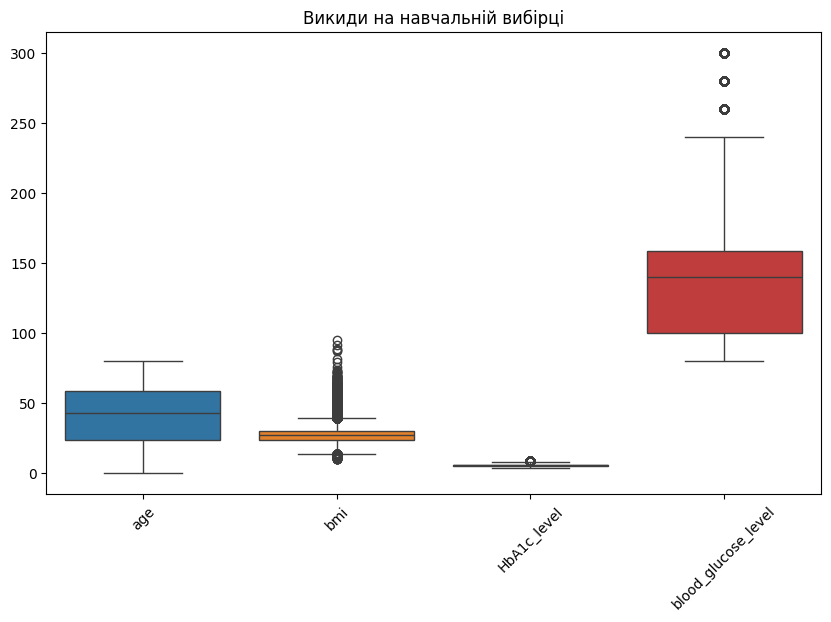

In [23]:
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train [continuous_cols])
plt.xticks (rotation=45)
plt.title('Викиди на навчальній вибірці')
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

На діаграмах виявлено можливі викиди в ознаках age, bmi, HbA1c_level та blood_glucose_level. Автоматично видаляти їх не будемо, оскільки екстремальні значення глюкози та HbA1c можуть мати важливе клінічне значення.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# Приклад для однієї ознаки ('bmi') не виконуємо в цій роботі:
# q1 = X_train ['bmi'].quantile(0.25)
#q3 = X_train['bmi'].quantile(0.75)
#iqr = q3 - q1
# mask = X_train['bmi'].between (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
# X_train = X_train.loc[mask].copy()
#y_train y_train.loc[mask].copy()
#X_test i y_test залишаються без змін!

Перевірити асиметрію розподілів ознак **на train**

In [24]:
X_train[continuous_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [25]:
print('Пропуски в train:', X_train.isna().sum().sum())
print('Пропуски в test:', X_test.isna().sum().sum())

Пропуски в train: 0
Пропуски в test: 0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

У наборі даних спостерігається дисбаланс класів: пацієнтів без діабету більше, ніж із діабетом. Кореляційний аналіз допомагає визначити взаємозв’язки між ознаками, а діаграми виявляють можливі викиди, які не видаляємо автоматично. Пропуски перевірено в навчальній і тестовій вибірках. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [33]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [34]:
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled, y_train
)

print('До балансування:')
print(y_train.value_counts())
print('\nПісля SMOTE:')
print(y_train_balanced.value_counts())

До балансування:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [35]:
models = {
    'LogisticRegression': LogisticRegression (max_iter=1000),
    'RidgeClassifier': RidgeClassifier(),
    'SGDClassifier': SGDClassifier (random_state=42),
    'SVC': SVC()
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



=== LogisticRegression ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



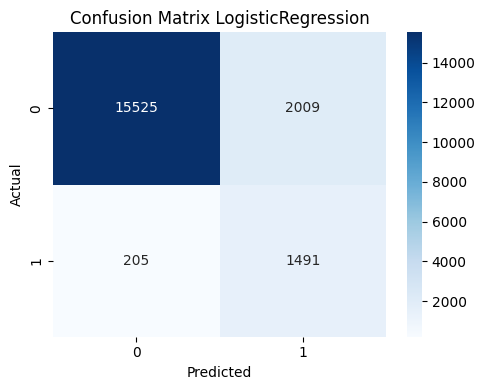


=== RidgeClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



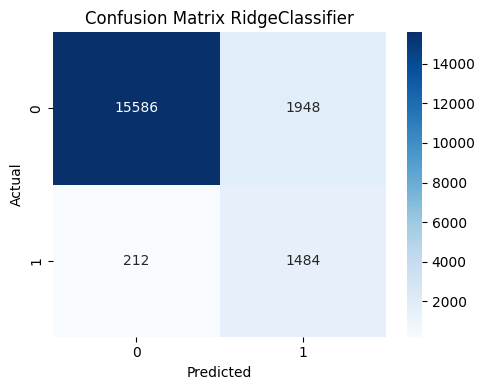


=== SGDClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



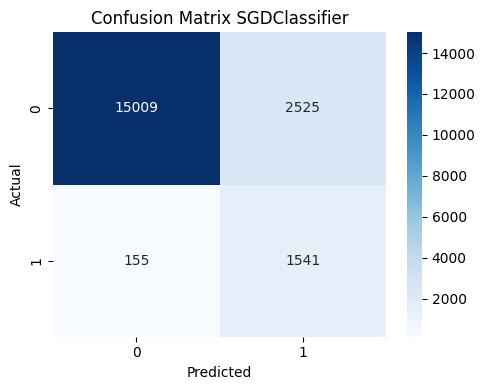


=== SVC ===
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



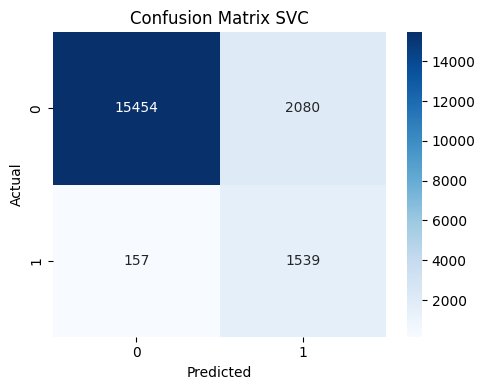

In [36]:
for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    predictions = model.predict(X_test_scaled)

    print(f"\n=== {name} ===")
    print(classification_report(y_test, predictions, zero_division=0))

    cm = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

Оптимізувати гіперпараметри


In [37]:
param_grids = {
    'LogisticRegression': {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'alpha': [0.1, 1.0, 10.0]
    },
    'SGDClassifier': {
        'loss': ['log_loss', 'hinge'],
        'alpha': [0.0001, 0.001, 0.01],
        'penalty': ['l2', 'l1']
    },
    'SVC': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [38]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [39]:
best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\nПідбір параметрів для {name}...")

    pipeline = Pipeline ([
        ('scaler', StandardScaler()),
        ('smote', SMOTE (random_state=42)),
        ('model', model)
    ])
    params = {'model__' + key: values for key, values in param_grids[name].items()}
    search = HalvingGridSearchCV(
        pipeline, params, scoring='f1', cv=3, factor=2,
        min_resources=300, random_state=42, n_jobs=1
    )
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print('Найкращі параметри: раметри:', search.best_params_)
    print(f'F1 на кросвалідації: {search.best_score_:.3f}')
    predictions = search.best_estimator_.predict(X_test)
    print('Класифікаційний звіт на test:')
    print(classification_report(y_test, predictions, zero_division=0))


Підбір параметрів для LogisticRegression...
Найкращі параметри: раметри: {'model__C': 0.01, 'model__solver': 'lbfgs'}
F1 на кросвалідації: 0.653
Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230


Підбір параметрів для RidgeClassifier...
Найкращі параметри: раметри: {'model__alpha': 10.0}
F1 на кросвалідації: 0.571
Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


Підбір параметрів 

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [40]:
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
print(f'Найкраща модель: {best_name}, F1 = {best_scores [best_name]:.3f}')

Найкраща модель: LogisticRegression, F1 = 0.653


In [41]:
random_indices = np.random.default_rng(42).choice(len(X_test), size=10, replace=False)
y_pred_best = best_model.predict(X_test.iloc[random_indices])
random_results_df = pd.DataFrame({
    'Index': X_test.iloc[random_indices].index,
    'True Values': y_test.iloc[random_indices].values,
    'Predicted Values': y_pred_best
})
random_results_df

,Index,True Values,Predicted Values
0,72555,0,1
1,42651,1,1
2,9181,0,0
3,67901,0,0
4,25253,0,0
5,58082,0,0
6,41116,0,1
7,63015,0,0
8,76480,0,0
9,15158,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

**1. Дисбаланс класів, кореляція та викиди.**

У початковій навчальній вибірці спостерігався значний дисбаланс класів: 70 130 записів належали до класу diabetes = 0, а 6 786 — до класу diabetes = 1. Для балансування навчальних даних було використано алгоритм SMOTE, після чого кількість записів обох класів становила 70 130. Кореляційний аналіз допоміг оцінити зв’язки між ознаками, а перевірка викидів на навчальній вибірці — виявити екстремальні значення числових показників. Виявлені можливі викиди не видаляли автоматично, оскільки вони можуть бути важливими для прогнозування діабету.

**2. Порівняння моделей та вибір найкращої.**

Було досліджено чотири моделі: Logistic Regression, Ridge Classifier, SGD Classifier і SVC. Найвище значення F1 на крос-валідації отримала Logistic Regression — 0,653, тому її було обрано найкращою моделлю. SGD Classifier показав F1 = 0,648, SVC — 0,622, а Ridge Classifier — 0,571. Recall для класу diabetes = 1 на тестовій вибірці становив 0,88 для перших трьох моделей, крім SVC, для якого він дорівнював 0,89. Отже, SVC виявив найбільшу частку позитивних випадків, але Logistic Regression продемонструвала найкращий результат за F1 на крос-валідації.

**3. Оптимальні гіперпараметри та помилки класифікації.**

Під час підбору гіперпараметрів отримано такі результати:
- Logistic Regression: C = 0.01, solver = 'lbfgs'.
- Ridge Classifier: alpha = 10.0.
- SGD Classifier: alpha = 0.01, loss = 'log_loss', penalty = 'l1'.
- SVC: C = 1, kernel = 'linear'.
Точність класифікації на тестовій вибірці становила 88–89%. Для класу diabetes = 1 значення precision становило 0,42–0,43, а recall — 0,88–0,89. Це свідчить про те, що моделі виявляють більшість позитивних випадків, але водночас мають значну кількість хибнопозитивних прогнозів. Для детальнішого аналізу помилок використовуються матриці плутанини.

**4. Обґрунтування поділу даних і використання SMOTE.**

Тестову вибірку було відокремлено від навчальної для незалежного оцінювання якості моделей. Масштабування виконувалося на навчальних даних за допомогою fit_transform, а до тестових даних застосовувався transform. SMOTE використовувався лише для балансування навчальної вибірки, тоді як тестова залишалася незмінною. Під час підбору гіперпараметрів масштабування та SMOTE були включені до Pipeline, що дозволило виконувати ці операції всередині крос-валідації та зменшити ризик витоку даних.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [42]:
!pip install -q xgboost lightgbm catboost

In [43]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

In [44]:
class_ratio = (y_train == 0).sum() / (y_train == 1).sum()

models_boosting = {
    'XGBoost': XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.1,
        scale_pos_weight=class_ratio,
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        device='cuda',
        random_state=42
    ),

    'LightGBM': LGBMClassifier(
        n_estimators=300,
        learning_rate=0.1,
        class_weight='balanced',
        random_state=42,
        verbosity=-1
    ),

    'CatBoost': CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.1,
        auto_class_weights='Balanced',
        task_type='GPU',
        random_seed=42,
        verbose=0
    )
}


========== XGBoost ==========


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [16:14:25] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



Класифікаційний звіт:
              precision    recall  f1-score   support

           0       0.99      0.92      0.95     17534
           1       0.50      0.89      0.64      1696

    accuracy                           0.91     19230
   macro avg       0.75      0.90      0.80     19230
weighted avg       0.95      0.91      0.92     19230



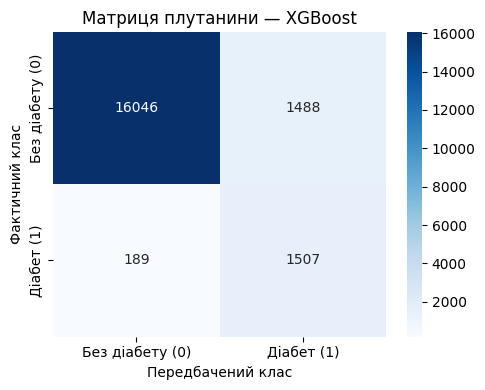


========== LightGBM ==========

Класифікаційний звіт:
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     17534
           1       0.54      0.87      0.66      1696

    accuracy                           0.92     19230
   macro avg       0.76      0.90      0.81     19230
weighted avg       0.95      0.92      0.93     19230



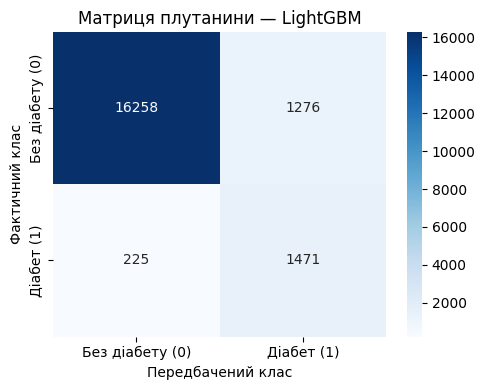


========== CatBoost ==========

Класифікаційний звіт:
              precision    recall  f1-score   support

           0       0.99      0.91      0.95     17534
           1       0.48      0.90      0.63      1696

    accuracy                           0.91     19230
   macro avg       0.74      0.90      0.79     19230
weighted avg       0.94      0.91      0.92     19230



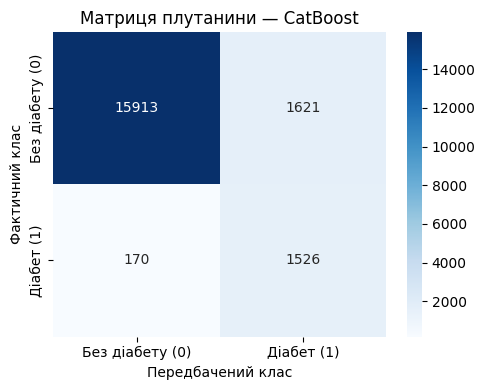

In [45]:
results_boosting = {}

for name, model in models_boosting.items():
    print(f'\n========== {name} ==========')

    try:
        model.fit(X_train, y_train)
    except Exception as e:
        print(f'Запуск на GPU не вдався: {e}')
        print('Пробуємо навчання на CPU...')

        if name == 'XGBoost':
            model.set_params(device='cpu')
        elif name == 'LightGBM':
            model.set_params(device_type='cpu')
        elif name == 'CatBoost':
            model.set_params(task_type='CPU')

        model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    print('\nКласифікаційний звіт:')
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Без діабету (0)', 'Діабет (1)'],
        yticklabels=['Без діабету (0)', 'Діабет (1)']
    )
    plt.title(f'Матриця плутанини — {name}')
    plt.xlabel('Передбачений клас')
    plt.ylabel('Фактичний клас')
    plt.tight_layout()
    plt.show()

    results_boosting[name] = {
        'model': model,
        'predictions': predictions,
        'report': classification_report(
            y_test, predictions, output_dict=True, zero_division=0
        ),
        'confusion_matrix': cm
    }

In [46]:
comparison = []

for name, result in results_boosting.items():
    report = result['report']

    comparison.append({
        'Model': name,
        'Accuracy': report['accuracy'],
        'Precision (diabetes=1)': report['1']['precision'],
        'Recall (diabetes=1)': report['1']['recall'],
        'F1-score (diabetes=1)': report['1']['f1-score']
    })

comparison_df = pd.DataFrame(comparison)
comparison_df = comparison_df.sort_values(
    by='F1-score (diabetes=1)',
    ascending=False
)

comparison_df.round(3)

,Model,Accuracy,Precision (diabetes=1),Recall (diabetes=1),F1-score (diabetes=1)
1,LightGBM,0.922,0.535,0.867,0.662
0,XGBoost,0.913,0.503,0.889,0.643
2,CatBoost,0.907,0.485,0.900,0.630


In [47]:
best_boosting = comparison_df.iloc[0]

print('Найкраща модель:', best_boosting['Model'])
print('F1-score:', round(best_boosting['F1-score (diabetes=1)'], 3))
print('Recall:', round(best_boosting['Recall (diabetes=1)'], 3))

Найкраща модель: LightGBM
F1-score: 0.662
Recall: 0.867


**Висновок до додаткового завдання**

У ході виконання додаткового завдання було реалізовано та порівняно три моделі машинного навчання: XGBoost, LightGBM і CatBoost. Для оцінювання їхньої якості використовувалися метрики Accuracy, Precision, Recall і F1-score для класу diabetes = 1, а також матриці плутанини.

Найкращий результат за F1-score показала LightGBM — 0,662, з Accuracy 0,922, Precision 0,535 і Recall 0,867. Модель XGBoost отримала F1-score 0,643 і Recall 0,889, а CatBoost — F1-score 0,630 і Recall 0,900. Отже, CatBoost виявила найбільшу частку реальних випадків діабету, проте LightGBM забезпечила кращий баланс між Precision і Recall та найвищу загальну точність.

Порівняння показало, що всі три моделі мають досить високі значення Recall, тобто виявляють більшість випадків діабету. Водночас значення Precision залишаються нижчими, що свідчить про наявність хибнопозитивних прогнозів. За сукупністю отриманих метрик LightGBM є найкращою моделлю серед трьох досліджених алгоритмів, якщо основним критерієм вибору є F1-score для позитивного класу.